In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

In [64]:
traj_file = "./remaster_sims/logs/sim.traj"
traj = pd.read_csv(traj_file, sep='\t')
traj_X = traj.loc[traj.loc[:, "population"] == "X", ["t", "value"]].reset_index(drop=True)
traj_X

,t,value
0,0.000000,1.0
1,0.003472,2.0
2,0.006419,3.0
3,0.010072,2.0
4,0.011066,3.0
...,...,...
11167,0.499888,960.0
11168,0.499901,961.0
11169,0.499939,962.0
11170,0.499961,961.0


In [86]:
measure_times = np.arange(0, 0.5, 0.5/180) # So we have wastewater measurements every day
len(measure_times)

180

In [114]:
# Creating wastewater measurements with added random noise
measures = []
for t in measure_times:
    idx = traj_X["t"].searchsorted(t, side="left") - 1
    if idx >= 0:
        measures.append(traj_X.loc[idx, "value"])
    else:
        measures.append(0)
    
measures = np.array(measures)
rng = np.random.default_rng(seed=42)
noise = rng.normal(loc=0, scale=0.5, size=measures.shape)
noisy_measures = measures + noise

start_date = datetime(2002, 1, 1)
measure_datetimes = [start_date + timedelta(days=years * 365.25) for years in measure_times]
measure_dates = [d.date() for d in measure_datetimes]

# print(f"measures: {measures}")
# print(f"noisy measures: {noisy_measures}")

measures_df = pd.DataFrame({"date": measure_dates,
                            "concentration": noisy_measures})
flows_df = pd.DataFrame({"date": measure_dates,
                         "flow": 1})


In [118]:
idx = traj_X["t"].searchsorted(0.2, side="left")
traj_X.loc[idx, :]

t         0.20003
value    56.00000
Name: 405, dtype: float64

In [113]:
measures_df.to_csv("./episewer_learn/concentrations.csv", index=False)
flows_df.to_csv("./episewer_learn/flows.csv", index=False)

<Axes: xlabel='t', ylabel='measure'>

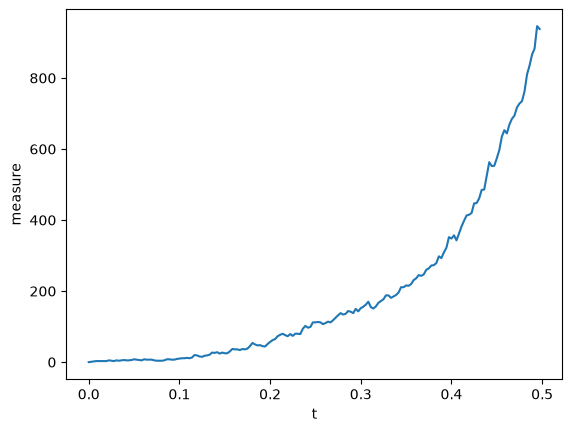

In [94]:
sns.lineplot(measures_df, x="t", y="measure")

In [89]:
idx = traj_X['t'].searchsorted(0.2, side='left') - 1
print(idx)
print(traj_X.loc[idx-1, :])

404
t         0.199833
value    56.000000
Name: 403, dtype: float64


In [91]:
x = np.arange(len(traj_X))

<Axes: xlabel='t', ylabel='value'>

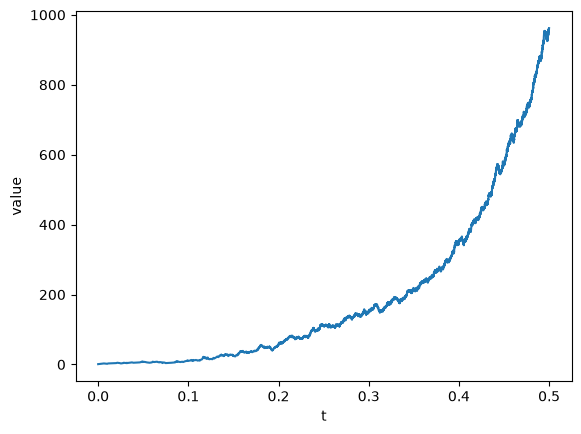

In [92]:
sns.lineplot(traj_X, x="t", y="value")